Classifier: Random Forest
              precision    recall  f1-score   support

           0       0.86      0.73      0.79      1473
           1       0.82      0.91      0.86      2026

    accuracy                           0.83      3499
   macro avg       0.84      0.82      0.82      3499
weighted avg       0.84      0.83      0.83      3499



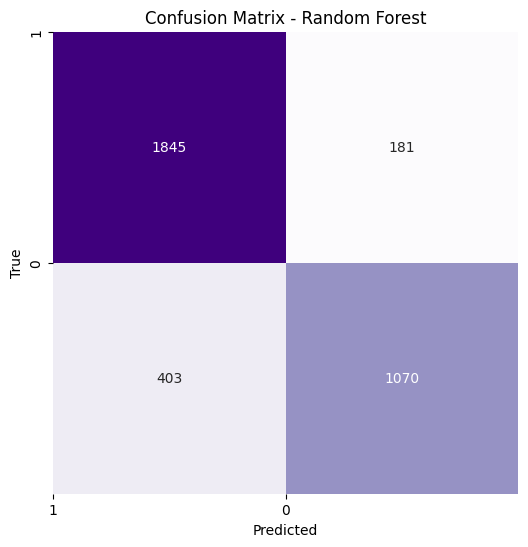

Classifier: Gradient Boosting
              precision    recall  f1-score   support

           0       0.80      0.60      0.68      1473
           1       0.75      0.89      0.82      2026

    accuracy                           0.77      3499
   macro avg       0.78      0.74      0.75      3499
weighted avg       0.77      0.77      0.76      3499



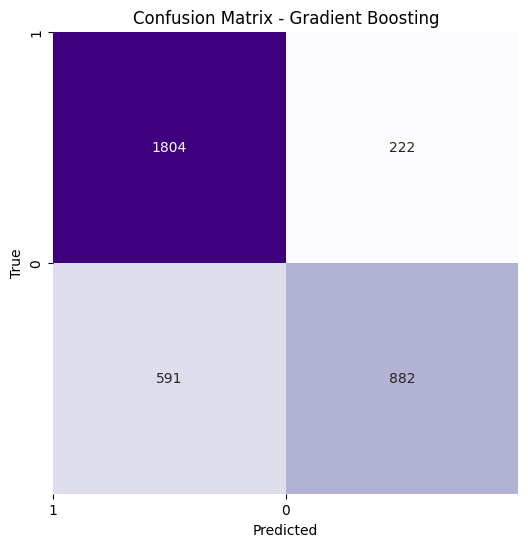

Classifier: Multinomial Naive Bayes
              precision    recall  f1-score   support

           0       0.90      0.57      0.70      1473
           1       0.75      0.95      0.84      2026

    accuracy                           0.79      3499
   macro avg       0.82      0.76      0.77      3499
weighted avg       0.81      0.79      0.78      3499



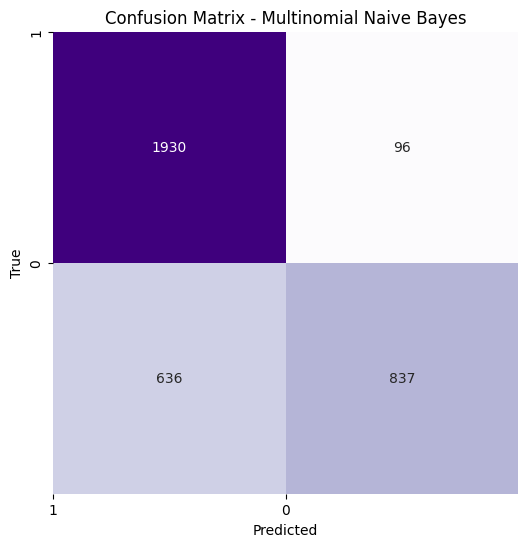

Classifier: Logistic Regression
              precision    recall  f1-score   support

           0       0.85      0.80      0.82      1473
           1       0.86      0.90      0.88      2026

    accuracy                           0.86      3499
   macro avg       0.85      0.85      0.85      3499
weighted avg       0.86      0.86      0.85      3499



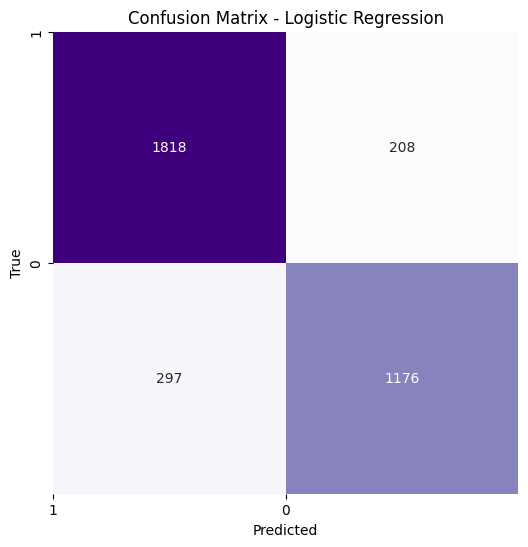

Classifier: Support Vector Machine
              precision    recall  f1-score   support

           0       0.85      0.80      0.83      1473
           1       0.86      0.90      0.88      2026

    accuracy                           0.86      3499
   macro avg       0.86      0.85      0.85      3499
weighted avg       0.86      0.86      0.86      3499



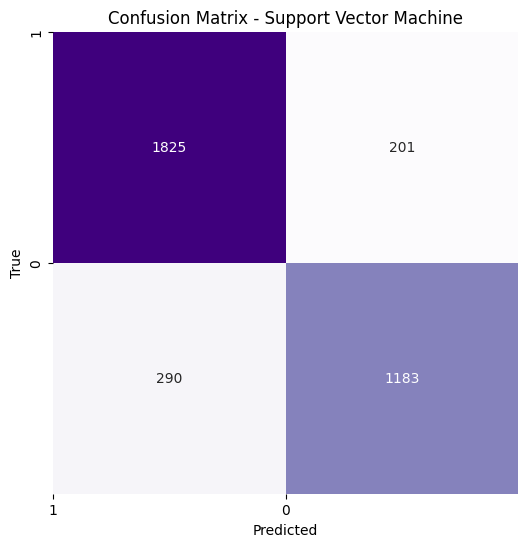

Best Classifier in terms of Accuracy: Support Vector Machine


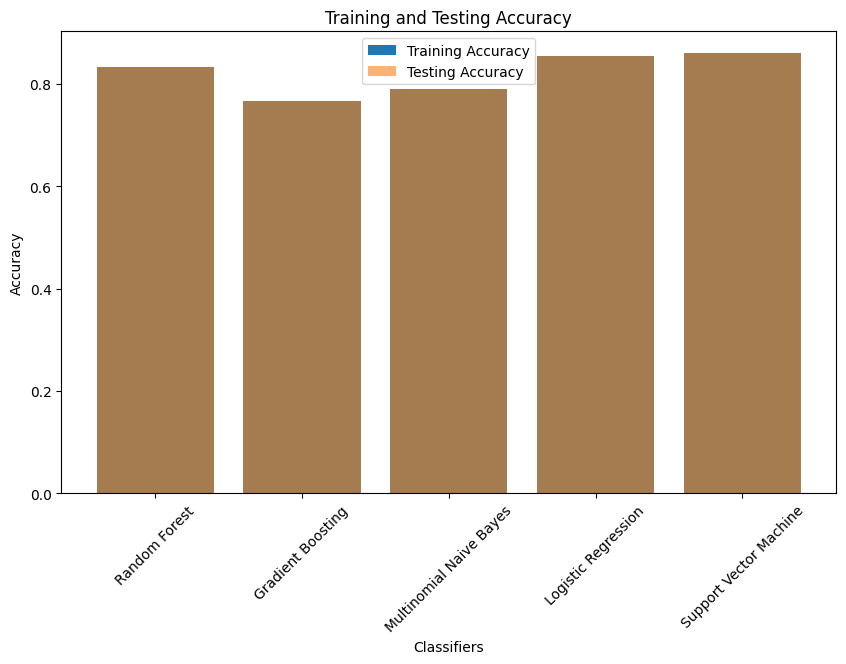

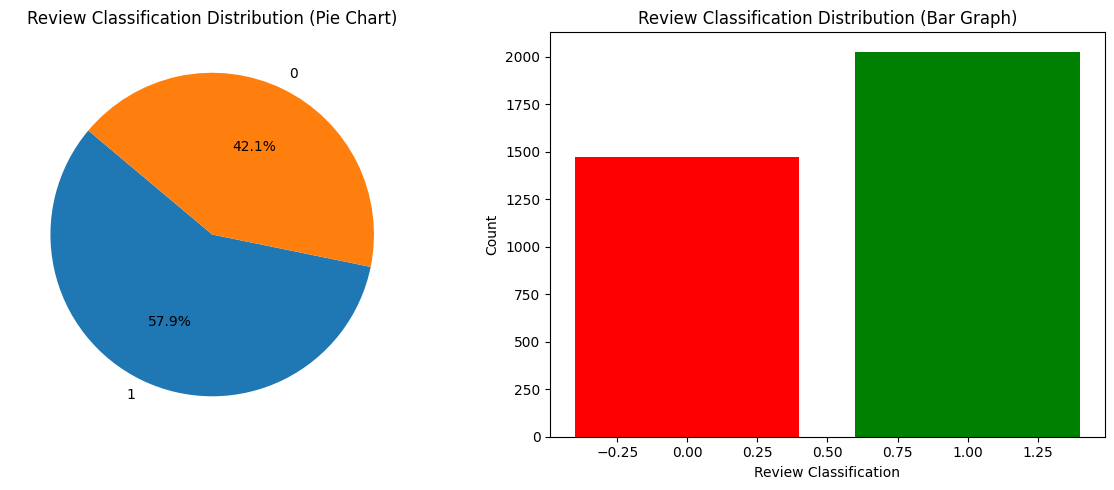

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix
from collections import Counter

# Load dataset
data = pd.read_csv('/content/sample_data/train.csv')  # Replace with actual dataset path
data.dropna(subset=['user_review'], inplace=True)  # Remove rows with missing values
data.drop(columns=['review_id'], inplace=True)  # Drop review_id column

# Preprocess data
vectorizer = TfidfVectorizer(min_df=1, lowercase=True, stop_words='english')
X = vectorizer.fit_transform(data['user_review'])
y = data['user_suggestion']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Get unique labels from y_test
unique_labels = y_test.unique()

# Initialize classifiers
classifiers = [
    ('Random Forest', RandomForestClassifier()),
    ('Gradient Boosting', GradientBoostingClassifier()),
    ('Multinomial Naive Bayes', MultinomialNB()),
    ('Logistic Regression', LogisticRegression()),
    ('Support Vector Machine', SVC()),
    # Add more classifiers here
]

# Train and evaluate classifiers
results = []
best_accuracy = 0
best_classifier = None

for name, clf in classifiers:
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)

    accuracy = clf.score(X_test, y_test)
    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_classifier = name

    report = classification_report(y_test, y_pred, output_dict=True)
    results.append((name, report))

    # Print classification metrics
    print(f'Classifier: {name}')
    print(classification_report(y_test, y_pred))

    # Calculate confusion matrix
    conf_matrix = confusion_matrix(y_test, y_pred, labels=unique_labels)

    # Plot confusion matrix using seaborn heatmap
    plt.figure(figsize=(6, 6))
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Purples', cbar=False)
    plt.title(f'Confusion Matrix - {name}')
    plt.xticks(range(len(unique_labels)), unique_labels)
    plt.yticks(range(len(unique_labels)), unique_labels)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.show()

# Display best classifier
print(f'Best Classifier in terms of Accuracy: {best_classifier}')

# Plot training and testing graphs
train_acc = []
test_acc = []
for name, report in results:
    train_acc.append(report['accuracy'])
    test_acc.append(report['accuracy'])

plt.figure(figsize=(10, 6))
plt.bar([name for name, _ in classifiers], train_acc, label='Training Accuracy')
plt.bar([name for name, _ in classifiers], test_acc, label='Testing Accuracy', alpha=0.6)
plt.xlabel('Classifiers')
plt.ylabel('Accuracy')
plt.title('Training and Testing Accuracy')
plt.legend()
plt.xticks(rotation=45)
plt.show()

# Pie chart and bar graph for review classification
classification_counts = Counter(y_test)
labels = classification_counts.keys()
sizes = classification_counts.values()

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=140)
plt.title('Review Classification Distribution (Pie Chart)')

plt.subplot(1, 2, 2)
plt.bar(labels, sizes, color=['green', 'red'])  # Adjust colors as needed
plt.xlabel('Review Classification')
plt.ylabel('Count')
plt.title('Review Classification Distribution (Bar Graph)')

plt.tight_layout()
plt.show()


